In [1]:
# Install required libraries
!pip install kaggle
!pip install tensorflow
!pip install matplotlib
!pip install scikit-learn
!pip install opencv-python

In [2]:
from google.colab import files
import os

# Upload your kaggle.json API key
files.upload()

# Move the uploaded kaggle.json to the correct directory and set permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [3]:
# Download the dataset from Kaggle (Tomato Ripeness Dataset)
!kaggle datasets download -d sumn2u/riped-and-unriped-tomato-dataset

# Unzip the downloaded file
!unzip riped-and-unriped-tomato-dataset.zip -d tomato_dataset

Dataset URL: https://www.kaggle.com/datasets/sumn2u/riped-and-unriped-tomato-dataset
License(s): CC-BY-SA-4.0
 92% 101M/110M [00:00<00:00, 1.06GB/s]
100% 110M/110M [00:00<00:00, 964MB/s] 
Archive:  riped-and-unriped-tomato-dataset.zip
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_1.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_10.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_11.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_12.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_13.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_14.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_15.jpeg  
  inflating: tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_16.jpeg  
  inflating: tomato_dataset/Riped and 

In [4]:
# Verify file paths and counts
base_dir = "/content/tomato_dataset/Riped and Unriped Tomato Dataset"
for root, dirs, files in os.walk(base_dir):
    print(root, "has", len(files), "files")

/content/tomato_dataset/Riped and Unriped Tomato Dataset has 0 files
/content/tomato_dataset/Riped and Unriped Tomato Dataset/Images has 177 files
/content/tomato_dataset/Riped and Unriped Tomato Dataset/labels has 177 files


In [6]:
import cv2
import matplotlib.pyplot as plt

images_dir = "/content/tomato_dataset/Riped and Unriped Tomato Dataset/Images"
labels_dir = "/content/tomato_dataset/Riped and Unriped Tomato Dataset/labels"

# Function to display one image with bounding boxes (YOLO format visualization)
def show_image_with_boxes(image_name):
    img_path = os.path.join(images_dir, image_name)
    label_path = os.path.join(labels_dir, image_name.replace('.jpg', '.txt').replace('.png', '.txt').replace('.jpeg', '.txt'))

    img = cv2.imread(img_path)
    if img is None:
        print(f"Could not load image: {img_path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape # Get image dimensions

    # Read YOLO label file and draw boxes
    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                # cls, x_center, y_center, width, height (normalized)
                cls, x, y, bw, bh = map(float, line.strip().split())

                # Convert normalized coordinates to pixel coordinates
                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)
                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)

                # Class 0 (unripe) = Green, Class 1+ (ripe/other) = Red
                color = (0, 255, 0) if int(cls) == 0 else (255, 0, 0)
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, f"Class {int(cls)}", (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()



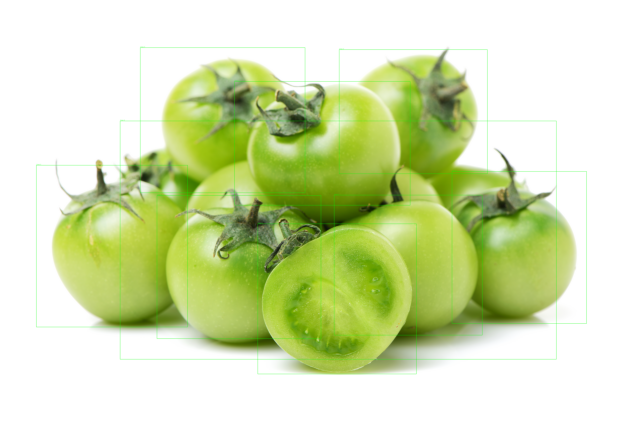

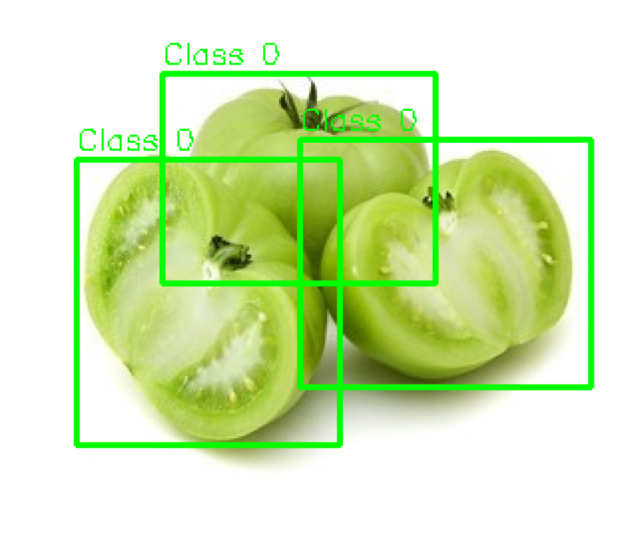

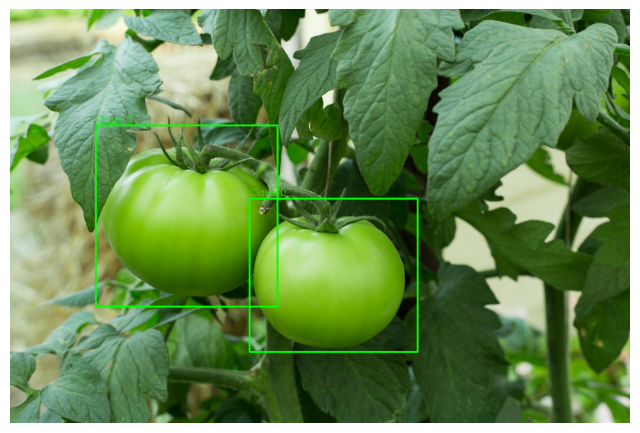

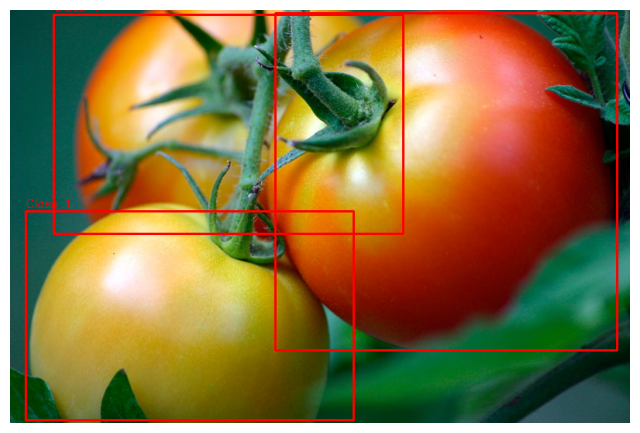

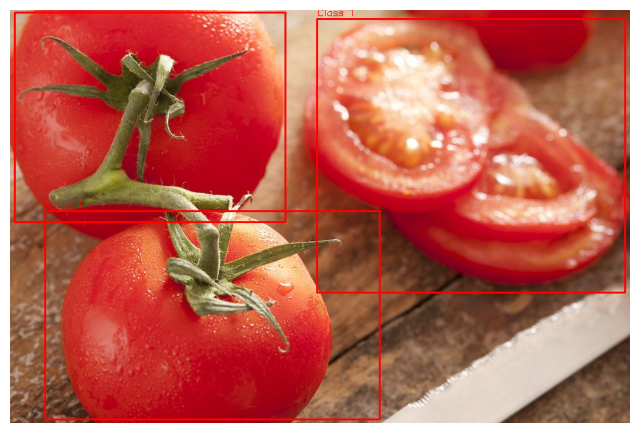

In [7]:
# Show a few random samples for visual inspection
sample_images = [f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.jpeg', '.png'))][:5]
for image_name in sample_images:
    show_image_with_boxes(image_name)

In [8]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

base_dir = "/content/tomato_dataset/Riped and Unriped Tomato Dataset/Images"

# Get all image paths
image_paths = [os.path.join(base_dir, img) for img in os.listdir(base_dir) if img.endswith(('.jpg', '.jpeg', '.png'))]
print("Total images found:", len(image_paths))

# Infer labels based on keywords in the filename (Crucial for Classification)
def get_label_from_name(filename):
    name = os.path.basename(filename).lower()
    if "unripe" in name or "unriped" in name:
        return 0  # class 0 = unripe (underripe)
    elif "ripe" in name and "unripe" not in name:
        return 1  # class 1 = ripe
    elif "over" in name:
        return 2  # class 2 = overripe
    else:
        return -1  # Ignore if classification label is ambiguous

labels = [get_label_from_name(p) for p in image_paths]

# Filter out unknown labels and split data
filtered = [(p, l) for p, l in zip(image_paths, labels) if l != -1]
image_paths, labels = zip(*filtered)
print("Usable images for classification:", len(image_paths))

# Split into train/validation sets (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    image_paths, labels, test_size=0.2, random_state=42, stratify=labels
)
print(f"Train samples: {len(X_train)} | Validation samples: {len(X_val)}")

Total images found: 177
Usable images for classification: 177
Train samples: 141 | Validation samples: 36


In [9]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
num_classes = 3 # unripe, ripe, overripe

# Image Preprocessing Function
def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3) # Decode to RGB
    img = tf.image.resize(img, IMG_SIZE)       # Resize for CNN input
    img = img / 255.0                          # Normalize pixel values
    return img, label

# Create optimized TensorFlow Datasets
train_ds = tf.data.Dataset.from_tensor_slices((list(X_train), list(y_train)))
train_ds = train_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((list(X_val), list(y_val)))
val_ds = val_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [17]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping # NEW IMPORT

input_shape = (*IMG_SIZE, 3)

# Define the CNN Model Architecture
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(), # Reduces feature maps to a single vector
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),             # Regularization to prevent overfitting
    layers.Dense(num_classes, activation='softmax') # Final classification layer (3 classes)
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy', # Suitable for integer labels
              metrics=['accuracy'])

# Display the model structure
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Define Early Stopping callback
# Stop training if 'val_loss' doesn't improve for 5 consecutive epochs
early_stopper = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15, # Max epochs is 15, but training may stop earlier
    callbacks=[early_stopper] # Apply the Early Stopping logic here
)

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 517ms/step - accuracy: 0.4400 - loss: 1.0034 - val_accuracy: 0.5556 - val_loss: 0.7108
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 447ms/step - accuracy: 0.6114 - loss: 0.7178 - val_accuracy: 0.5556 - val_loss: 0.6077
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 436ms/step - accuracy: 0.6560 - loss: 0.6263 - val_accuracy: 0.9167 - val_loss: 0.4203
Epoch 4/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 479ms/step - accuracy: 0.8690 - loss: 0.4043 - val_accuracy: 0.9444 - val_loss: 0.2692
Epoch 5/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 437ms/step - accuracy: 0.8502 - loss: 0.3283 - val_accuracy: 0.9444 - val_loss: 0.1805
Epoch 6/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 436ms/step - accuracy: 0.9139 - loss: 0.1969 - val_accuracy: 0.9722 - val_loss: 0.1481
Epoch 7/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 413ms/step - accuracy: 0.8862 - loss: 0.2724 - val_accuracy: 0.9444 - val_loss: 0.1499
Epoch 8/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 527ms/step - accuracy: 0.9174 - loss: 0.2246 - val_accuracy: 0.9722 - val_l

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.9627 - loss: 0.1357 
Validation Accuracy: 0.9722


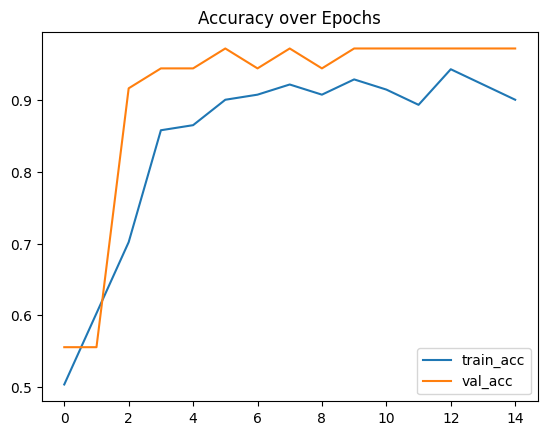

In [19]:
# Final evaluation on the validation set
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation Accuracy: {val_acc:.4f}")

# Plotting Accuracy over Epochs
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('Accuracy over Epochs')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
Classification Report:

              precision    recall  f1-score   support

      unripe       0.94      1.00      0.97        16
        ripe       1.00      0.95      0.97        20
    overripe       0.00      0.00      0.00         0

    accuracy                           0.97        36
   macro avg       0.65      0.65      0.65        36
weighted avg       0.97      0.97      0.97        36



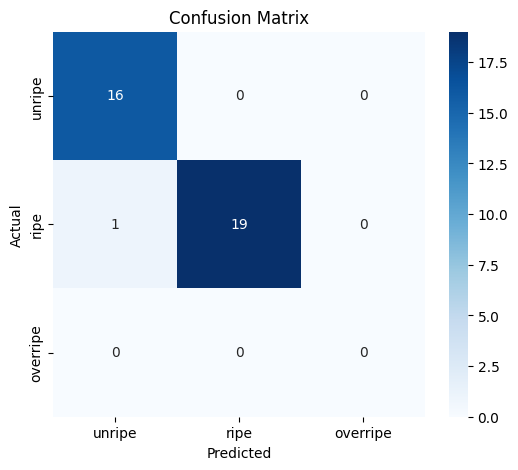

In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Collect true labels and predictions for the entire validation set
y_true = []
y_pred_probs = []

# Iterate over the validation dataset to get predictions
for images, labels in val_ds:
    y_true.extend(labels.numpy())
    y_pred_probs.extend(model.predict(images))

y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# Generate Classification Report (Precision, Recall, F1-score)
class_names = ['unripe', 'ripe', 'overripe']
report = classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
)
print("Classification Report:\n")
print(report)

# Generate and Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [21]:
# Save the trained model for later use
model.save("/content/tomato_ripeness_model.h5")
print("Model saved as tomato_ripeness_model.h5")

Model saved as tomato_ripeness_model.h5


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


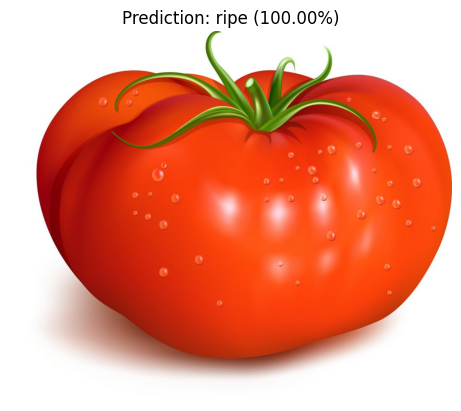

Predicted Class: ripe | Confidence: 100.00%


In [22]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Load the trained model
model = tf.keras.models.load_model("/content/tomato_ripeness_model.h5")

# Define a hard-coded test image path
image_path = "/content/tomato_dataset/Riped and Unriped Tomato Dataset/Images/riped_tomato_40.jpeg"

# Preprocess the test image
IMG_SIZE = (128, 128)
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(img_rgb, IMG_SIZE)
img_normalized = img_resized / 255.0
img_input = np.expand_dims(img_normalized, axis=0) # Add batch dimension

# Predict class
preds = model.predict(img_input)
pred_class = np.argmax(preds, axis=1)[0]
confidence = float(np.max(preds))

# Map index to label
class_names = ["unripe", "ripe", "overripe"]
pred_label = class_names[pred_class]

# Show result
plt.imshow(img_rgb)
plt.axis("off")
plt.title(f"Prediction: {pred_label} ({confidence*100:.2f}%)")
plt.show()

print(f"Predicted Class: {pred_label} | Confidence: {confidence*100:.2f}%")